# 1. Título

## TURMAS 2021 - Fundação Universidade Federal de Sergipe - UFS

# 2. Membros (nome e número de matrícula)

**Nome - Matrícula**

Davi Fraga Marques Neves

Mateus Henrique Souza Silva

Matheus Vaz Leal Lima

Vinicius Trindade Dias Abel **-** 2020007112

# 3. Descrição dos dados (qual a URL? qual o domínio? como os dados foram processados?)

O *dataset* contendo os dados bases para utilização no desenvolvimento do trabalho prático foram retirados do site governamental, [dados.gov.br](https://dados.gov.br/). A URL para acessar os dados públicos é: [turmas-ufs/turmas-de-2021](https://dados.gov.br/dataset/turmas-ufs/resource/tur-csv-turmas-de-2021).

Estes dados são provenientes da Fundação Universidade Federal de Sergipe (UFS) e representam as Turmas de 2021 da Universidade, contendo assim, informações sobre turmas, docentes, componente curricular, local e campus.

Para utilizar na prática, tivemos que adequar e normalizar a rede de dados, já que não estava pronto para o consumo nosso. A normalização compreendeu-se em alteração de nomes dos atributos, criação de tabelas para não termos somente uma como estava no *dataset* e também novas para relacionamentos de muitos para muitos, novos atributos criados como os identificadores das tabelas e se fez necessário também a exclusão de colunas não necessárias, como a "field_18". Além disso, tivemos uma inconsistência nos dados, onde estava como vazio, processamos como *NULL*.

O resultado final é de 7 tabelas relacionais e 30 atributos ao todo.

In [2]:
import io
import sqlite3
import pandas as pd

conn = sqlite3.connect('/tmp/consult.db')
cursor = conn.cursor()

f = io.open('/tmp/tp_ibd_sqlite_final.sql', 'r', encoding='utf-8')
sql = f.read()
cursor.executescript(sql)

# 4. Diagrama ER

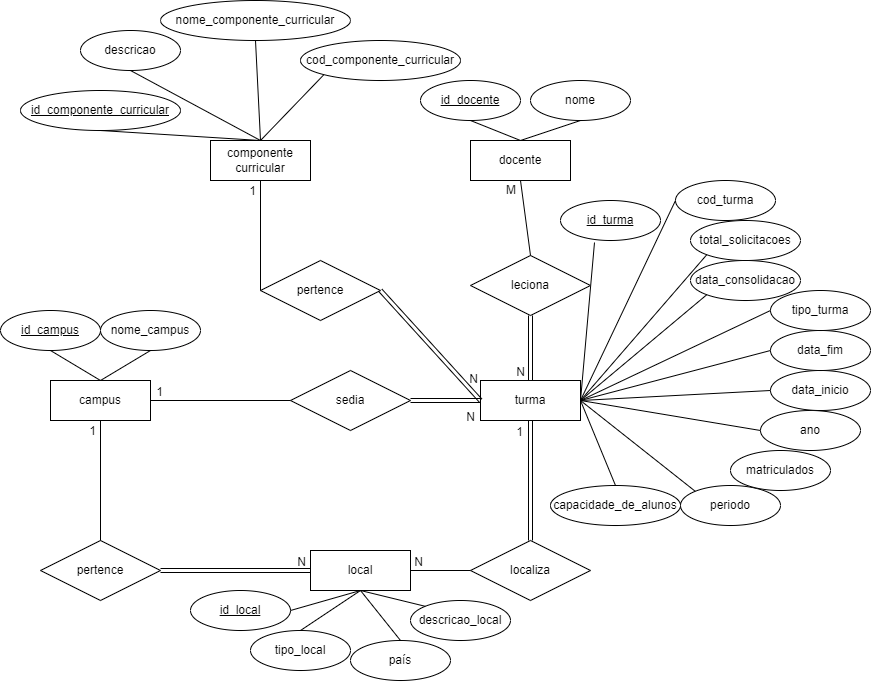

# 5. Diagrama relacional

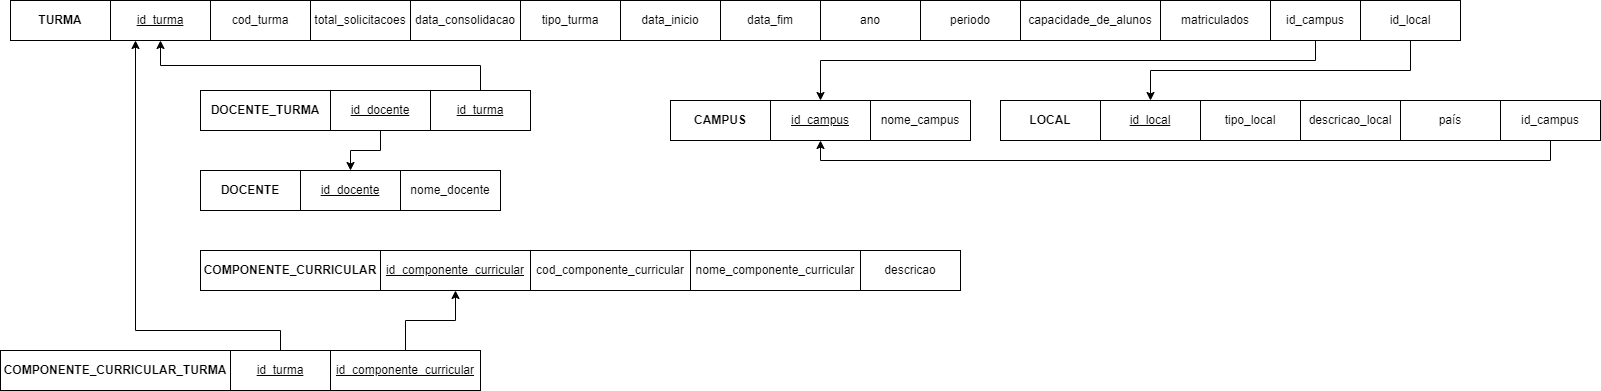

# 6. Consultas

## 6.1 Duas consultas envolvendo seleção e projeção

### 6.1.1 Total de solicitações das turmas consolidadas em 2021

In [ ]:
query = """
SELECT
  SUM(T.TOTAL_SOLICITACOES)
FROM 
  TURMA T
WHERE
  T.DATA_CONSOLIDACAO BETWEEN '01/01/2021' AND '31/12/2021'
"""

df = pd.read_sql_query(query, conn)
df

,SUM(T.TOTAL_SOLICITACOES)
0,94793


In [ ]:
query = """
SELECT
  SUM(T.TOTAL_SOLICITACOES)
FROM 
  TURMA T
WHERE
  T.DATA_CONSOLIDACAO >= '01/01/2021' AND T.DATA_CONSOLIDACAO <= '31/12/2021'
"""

df = pd.read_sql_query(query, conn)
df

,SUM(T.TOTAL_SOLICITACOES)
0,94793


### 6.1.2 Capacidade de alunos das matéria do primeiro período de 2021

In [ ]:
query = """
SELECT
  T.CAPACIDADE_DE_ALUNOS
FROM 
  TURMA T
WHERE
  T.PERIODO = 1 AND T.ANO = 2021
GROUP BY
  T.ID_TURMA
"""

df = pd.read_sql_query(query, conn)
df

,capacidade_de_alunos
0,20.0
1,20.0
2,20.0
3,20.0
4,1.0
...,...
6183,15.0
6184,2.0
6185,5.0
6186,25.0


In [ ]:
query = """
SELECT
  T.CAPACIDADE_DE_ALUNOS
FROM 
  TURMA AS T, TURMA AS TUR 
WHERE
  T.PERIODO = 1 AND TUR.ANO = 2021 AND T.ID_TURMA = TUR.ID_TURMA AND T.ANO = TUR.ANO
GROUP BY
  T.ID_TURMA
"""

df = pd.read_sql_query(query, conn)
df

,capacidade_de_alunos
0,20.0
1,20.0
2,20.0
3,20.0
4,1.0
...,...
6183,15.0
6184,2.0
6185,5.0
6186,25.0


## 6.2 Três consultas envolvendo junção de duas relações

### 6.2.1 Nomes dos campi que oferecem as matérias de 2021

In [ ]:
query = """
SELECT
  TC.NOME_CAMPUS
FROM
  (TURMA NATURAL JOIN CAMPUS) AS TC
WHERE
  TC.ANO = 2021
GROUP BY
  TC.ID_CAMPUS
"""

df = pd.read_sql_query(query, conn)
df

,nome_campus
0,CAMPUS UNIVERSITÁRIO PROF. JOÃO CARDOSO NASCIM...
1,FUNDACAO UNIVERSIDADE FEDERAL DE SERGIPE
2,CAMPUS UNIVERSITARIO ALBERTO CARVALHO
3,CAMPUS DO SERTÃO
4,CAMPUS DE LARANJEIRAS
5,CAMPUS UNIVERSITÁRIO PROF. ANTÔNIO GARCIA FILHO
6,CAMPUS RURAL
7,NÃO INFORMADO


In [ ]:
query = """
SELECT
  C.NOME_CAMPUS
FROM
  TURMA T, CAMPUS C
WHERE
  T.ANO = 2021
GROUP BY
  C.ID_CAMPUS
"""

df = pd.read_sql_query(query, conn)
df

,nome_campus
0,CAMPUS UNIVERSITÁRIO PROF. JOÃO CARDOSO NASCIM...
1,FUNDACAO UNIVERSIDADE FEDERAL DE SERGIPE
2,CAMPUS UNIVERSITARIO ALBERTO CARVALHO
3,CAMPUS DO SERTÃO
4,CAMPUS DE LARANJEIRAS
5,CAMPUS UNIVERSITÁRIO PROF. ANTÔNIO GARCIA FILHO
6,CAMPUS RURAL
7,NÃO INFORMADO


### 6.2.2 Professores que lecionam matérias consolidadas em 2021

In [13]:
query = """
SELECT
  T.NOME_DOCENTE
FROM 
  (TURMA NATURAL JOIN DOCENTE) AS T
WHERE
  T.DATA_CONSOLIDACAO >= '01/01/2021' AND T.DATA_CONSOLIDACAO <= '31/12/2021'
GROUP BY
  T.ID_DOCENTE
"""

df = pd.read_sql_query(query, conn)
df

,nome_docente
0,"SILVÂNIO SILVÉRIO LOPES DA COSTA, JOEL ALONSO ..."
1,JOSE JAILTON MARQUES
2,"BRUNO SANTOS SOUZA, INAURA CAROLINA CARNEIRO D..."
3,BRUNO SANTOS SOUZA
4,RICARDO AURELIO CARVALHO SAMPAIO
...,...
2508,"JOSE KAIO MAX ALVES DO REGO, LEDJANE SILVA BAR..."
2509,"RAQUEL OLIVEIRA LIMA, HANNAH LICIA CRUZ GALVAO"
2510,"ROSIVÂNIA DA PAIXÃO SILVA OLIVEIRA, JOSÉ BEZER..."
2511,"VITOR HUGO SIMON, JOAO PAULO LOBO DOS SANTOS, ..."


In [15]:
query = """
SELECT
  T.NOME_DOCENTE
FROM 
  (TURMA NATURAL JOIN DOCENTE) AS T
WHERE
  T.DATA_CONSOLIDACAO BETWEEN '01/01/2021' AND '31/12/2021'
GROUP BY
  T.ID_DOCENTE
"""

df = pd.read_sql_query(query, conn)
df

,nome_docente
0,"SILVÂNIO SILVÉRIO LOPES DA COSTA, JOEL ALONSO ..."
1,JOSE JAILTON MARQUES
2,"BRUNO SANTOS SOUZA, INAURA CAROLINA CARNEIRO D..."
3,BRUNO SANTOS SOUZA
4,RICARDO AURELIO CARVALHO SAMPAIO
...,...
2508,"JOSE KAIO MAX ALVES DO REGO, LEDJANE SILVA BAR..."
2509,"RAQUEL OLIVEIRA LIMA, HANNAH LICIA CRUZ GALVAO"
2510,"ROSIVÂNIA DA PAIXÃO SILVA OLIVEIRA, JOSÉ BEZER..."
2511,"VITOR HUGO SIMON, JOAO PAULO LOBO DOS SANTOS, ..."


### 6.2.3 ID do componente curricular da turma com mais matriculados

In [ ]:
query = """
SELECT
  C.ID_COMPONENTE_CURRICULAR
FROM 
  TURMA T NATURAL JOIN COMPONENTE_CURRICULAR_TURMA C
ORDER BY
  T.MATRICULADOS DESC
LIMIT 1
"""

df = pd.read_sql_query(query, conn)
df

,id_componente_curricular
0,1903


In [ ]:
query = """
SELECT
  C.ID_COMPONENTE_CURRICULAR
FROM 
  TURMA T, COMPONENTE_CURRICULAR_TURMA C
WHERE
  T.ID_TURMA = C.ID_TURMA
ORDER BY
  T.MATRICULADOS DESC
LIMIT 1
"""

df = pd.read_sql_query(query, conn)
df

,id_componente_curricular
0,1903


## 6.3 Três consultas envolvendo junção de três ou mais relações

### 6.3.1 Professores que dão aulas para pelo menos uma turma pelo 'Google Classroom'

In [3]:
query = """
SELECT
  D.NOME_DOCENTE
FROM 
  TURMA T NATURAL JOIN LOCAL L, DOCENTE_TURMA DT NATURAL JOIN DOCENTE D
WHERE
  T.ID_TURMA = DT.ID_TURMA AND L.DESCRICAO_LOCAL = 'Google Classroom'
GROUP BY
  D.ID_DOCENTE
"""

df = pd.read_sql_query(query, conn)
df

,nome_docente
0,RICARDO COSTA DOS SANTOS
1,ANDREZA SANTOS CRUZ MAYNARD
2,SAULO HENRIQUE SOUZA SILVA
3,"PATRICIA DE SOUSA NUNES SILVA, DAGOBERTO DE OL..."
4,JOSÉ GENIVALDO MÁRTIRES
5,SILVANIA DA SILVA COSTA
6,"MARCELO OLIVEIRA UCHOA, THAIS FERNANDA VICENTE..."
7,ROBSON ANDRADE DE JESUS
8,DAGOBERTO DE OLIVEIRA MACHADO
9,ANA MARIA SEVERO CHAVES


In [ ]:
query = """
SELECT
  D.NOME_DOCENTE
FROM 
  DOCENTE D NATURAL JOIN DOCENTE_TURMA DT NATURAL JOIN TURMA T NATURAL JOIN LOCAL L
WHERE
  L.DESCRICAO_LOCAL = 'Google Classroom'
GROUP BY
  D.ID_DOCENTE
"""

df = pd.read_sql_query(query, conn)
df

,nome_docente
0,RICARDO COSTA DOS SANTOS
1,ANDREZA SANTOS CRUZ MAYNARD
2,SAULO HENRIQUE SOUZA SILVA
3,"PATRICIA DE SOUSA NUNES SILVA, DAGOBERTO DE OL..."
4,JOSÉ GENIVALDO MÁRTIRES
5,SILVANIA DA SILVA COSTA
6,"MARCELO OLIVEIRA UCHOA, THAIS FERNANDA VICENTE..."
7,ROBSON ANDRADE DE JESUS
8,DAGOBERTO DE OLIVEIRA MACHADO
9,ANA MARIA SEVERO CHAVES


### 6.3.2 Docentes que dão aulas para uma turma de um Campus do país ‘Brasil’ 

In [ ]:
query = """
SELECT
  D.NOME_DOCENTE
FROM 
  TURMA T NATURAL JOIN LOCAL L, DOCENTE_TURMA DT NATURAL JOIN DOCENTE D
WHERE
  T.ID_TURMA = DT.ID_TURMA AND L.PAIS = 'Brasil'
GROUP BY
  D.ID_DOCENTE
"""

df = pd.read_sql_query(query, conn)
df

,nome_docente
0,"SILVÂNIO SILVÉRIO LOPES DA COSTA, JOEL ALONSO ..."
1,JOSE JAILTON MARQUES
2,"BRUNO SANTOS SOUZA, INAURA CAROLINA CARNEIRO D..."
3,BRUNO SANTOS SOUZA
4,RICARDO AURELIO CARVALHO SAMPAIO
...,...
2483,"CRISTINA FERRAZ SILVA, VINICIUS SILVA VARANDAS"
2484,"JOSE KAIO MAX ALVES DO REGO, LEDJANE SILVA BAR..."
2485,"RAQUEL OLIVEIRA LIMA, HANNAH LICIA CRUZ GALVAO"
2486,"VITOR HUGO SIMON, JOAO PAULO LOBO DOS SANTOS, ..."


In [ ]:
query = """
SELECT
  D.NOME_DOCENTE
FROM 
  DOCENTE D NATURAL JOIN DOCENTE_TURMA DT NATURAL JOIN TURMA T NATURAL JOIN LOCAL L
WHERE
  L.PAIS = 'Brasil'
GROUP BY
  D.ID_DOCENTE
"""

df = pd.read_sql_query(query, conn)
df

,nome_docente
0,"SILVÂNIO SILVÉRIO LOPES DA COSTA, JOEL ALONSO ..."
1,JOSE JAILTON MARQUES
2,"BRUNO SANTOS SOUZA, INAURA CAROLINA CARNEIRO D..."
3,BRUNO SANTOS SOUZA
4,RICARDO AURELIO CARVALHO SAMPAIO
...,...
2483,"CRISTINA FERRAZ SILVA, VINICIUS SILVA VARANDAS"
2484,"JOSE KAIO MAX ALVES DO REGO, LEDJANE SILVA BAR..."
2485,"RAQUEL OLIVEIRA LIMA, HANNAH LICIA CRUZ GALVAO"
2486,"VITOR HUGO SIMON, JOAO PAULO LOBO DOS SANTOS, ..."


### 6.3.3 Local que tem aulas de uma turma com componente curricular ‘MODELAGEM AMBIENTAL’

In [ ]:
query = """
SELECT
  L.ID_LOCAL
FROM 
  LOCAL L NATURAL JOIN TURMA T NATURAL JOIN COMPONENTE_CURRICULAR_TURMA CT NATURAL JOIN COMPONENTE_CURRICULAR C
WHERE
  C.NOME_COMPONENTE_CURRICULAR = 'MODELAGEM AMBIENTAL'
GROUP BY
  L.ID_LOCAL
"""

df = pd.read_sql_query(query, conn)
df

,id_local
0,8


In [ ]:
query = """
SELECT
  L.ID_LOCAL
FROM 
  TURMA T NATURAL JOIN LOCAL L, COMPONENTE_CURRICULAR_TURMA CT NATURAL JOIN COMPONENTE_CURRICULAR C
WHERE
  C.NOME_COMPONENTE_CURRICULAR = 'MODELAGEM AMBIENTAL' AND T.ID_TURMA = CT.ID_TURMA
GROUP BY
  L.ID_LOCAL
"""

df = pd.read_sql_query(query, conn)
df

,id_local
0,8


## 6.4 Duas consultas envolvendo agregação sobre junção de duas ou mais relações

### 6.4.1 Número de alunos matriculados em turmas do primeiro período de 2021

In [19]:
query = """
SELECT
  SUM(T.MATRICULADOS) AS 'NUMERO_ALUNOS'
FROM 
  TURMA T
WHERE
  T.PERIODO = 1 AND T.ANO = 2021
"""

df = pd.read_sql_query(query, conn)
df

,NUMERO_ALUNOS
0,117815


In [21]:
query = """
SELECT
  SUM(T.MATRICULADOS) AS 'NUMERO_ALUNOS'
FROM 
  TURMA T JOIN TURMA TUR ON T.ID_TURMA = TUR.ID_TURMA
WHERE
  T.PERIODO = 1 AND TUR.ANO = 2021
"""

df = pd.read_sql_query(query, conn)
df

,NUMERO_ALUNOS
0,117815


### 6.4.2 Número de turmas que têm aulas em ‘Google Classroom’

In [11]:
query = """
SELECT
  COUNT(*) AS 'NUMERO_TURMAS'
FROM 
  TURMA T NATURAL JOIN LOCAL L
WHERE
  L.DESCRICAO_LOCAL = 'Google Classroom'
GROUP BY
  T.ID_LOCAL
"""

df = pd.read_sql_query(query, conn)
df

,NUMERO_TURMAS
0,94


In [18]:
query = """
SELECT
  COUNT(T.ID_TURMA) AS 'NUMERO_TURMAS'
FROM 
  TURMA T NATURAL JOIN LOCAL L
WHERE
  L.DESCRICAO_LOCAL = 'Google Classroom'
GROUP BY
  T.ID_LOCAL
"""

df = pd.read_sql_query(query, conn)
df

,NUMERO_TURMAS
0,94


# 7. Autoavaliação dos membros

**Davi Fraga Marques Neves:**

Escolha do banco de dados, elaboração dos modelos ER e Relacional, elaboração das consultas e documentação 

**Mateus Henrique Souza Silva:**

Escolha do banco de dados, elaboração dos modelos ER e Relacional, elaboração das consultas e documentação 

**Matheus Vaz Leal Lima:**

Escolha do banco de dados, elaboração dos modelos ER e Relacional, elaboração das consultas e documentação 

**Vinicius Trindade Dias Abel:**

Escolha do banco de dados, elaboração dos modelos ER e Relacional, elaboração das consultas e documentação 